# 1. Exploratory Data Analysis: Big Black Money Transactions



This notebook explores `Big_Black_Money_Dataset.csv` to understand its structure, data quality, transaction patterns, and possible preparation steps for later analysis or modeling. The analysis is descriptive: it does not establish that a transaction is actually illicit, nor does it assume which field should be the final prediction target. Sections 1.10 to 1.10.6 then audit the dataset's provenance, testing whether the structure described earlier reflects a recorded process or the distributions it was generated from.



## Table of Contents



- [1.1 Introduction](#11-introduction)

- [1.2 Preparation](#12-preparation)

- [1.3 Dataset Summary](#13-dataset-summary)
  - [1.3.1 Initial Preview and Structure](#131-initial-preview-and-structure)

- [1.4 Missing Values and Duplicates](#14-missing-values-and-duplicates)

- [1.5 Univariate Analysis](#15-univariate-analysis)
  - [1.5.1 Numerical Variables](#151-numerical-variables)
  - [1.5.2 Categorical Variables](#152-categorical-variables)

- [1.6 Temporal Analysis](#16-temporal-analysis)

- [1.7 Bivariate Analysis](#17-bivariate-analysis)
  - [1.7.1 Numeric Relationships](#171-numeric-relationships)
  - [1.7.2 Average Risk Score by Country](#172-average-risk-score-by-country)

- [1.8 Feature Engineering](#18-feature-engineering)

- [1.10 Provenance Audit](#110-provenance-audit)
  - [1.10.1 Timestamp Regularity](#1101-timestamp-regularity)
  - [1.10.2 Distributional Tests](#1102-distributional-tests)
  - [1.10.3 Leading-Digit Analysis](#1103-leading-digit-analysis)
  - [1.10.4 Entity Consistency](#1104-entity-consistency)
  - [1.10.5 Independence Across Columns](#1105-independence-across-columns)
  - [1.10.6 Audit Summary](#1106-audit-summary)

- [1.16 Final Insights](#116-final-insights)
  - [1.16.1 Preprocessing Recommendations](#1161-preprocessing-recommendations)
  - [1.16.2 Final Dataset Snapshot](#1162-final-dataset-snapshot)



## 1.1 Introduction



The dataset contains transaction-level records with amounts, dates, countries, transaction types, industries, financial institutions, and several fields related to reporting and money-laundering risk. The goal is to inspect these variables, identify data-quality concerns, and document preprocessing options before any modeling decisions are made.


In [16]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")

DATASET_NAME = "Big_Black_Money_Dataset.csv"
possible_paths = [
    Path(DATASET_NAME),
    Path("2ndProject") / DATASET_NAME,
]
dataset_path = next((path for path in possible_paths if path.exists()), None)
if dataset_path is None:
    raise FileNotFoundError(
        f"Could not find {DATASET_NAME}. Place it beside this notebook "
        "or run the notebook from the repository root."
    )

raw_data = pd.read_csv(dataset_path)
data = raw_data.copy()

# Convert fields that should be numeric or temporal for reliable analysis.
for column in ["Amount (USD)", "Money Laundering Risk Score", "Shell Companies Involved"]:
    data[column] = pd.to_numeric(data[column], errors="coerce")

data["Date of Transaction"] = pd.to_datetime(
    data["Date of Transaction"], errors="coerce"
)
data["Reported by Authority"] = (
    data["Reported by Authority"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"true": True, "false": False})
)

print(f"Loaded {len(data):,} transactions from {dataset_path.resolve()}")
print(f"Dataset shape: {data.shape[0]:,} rows x {data.shape[1]} columns")

Loaded 10,000 transactions from C:\Users\maria\Documents\Universidade\Capstone\Capstone-Project\2ndProject\Big_Black_Money_Dataset.csv
Dataset shape: 10,000 rows x 14 columns


## 1.2 Preparation

The dataset is loaded from the same folder as this notebook when possible, with a repository-root fallback. A copy named `data` is used for exploration, while `raw_data` remains available as the untouched import. Date, numeric, and Boolean-like fields are parsed explicitly so later summaries and plots use the intended types.

## 1.3 Dataset Summary

### 1.3.1 Initial Preview and Structure

In [17]:
display(data.head())
print("\nDataset information:")
data.info()

print("\nNumerical descriptive statistics:")
display(data.describe(include=[np.number]).T)

print("\nCategorical descriptive statistics:")
display(data.describe(include=["object", "string", "bool"]).T)

,Transaction ID,Country,Amount (USD),Transaction Type,Date of Transaction,Person Involved,Industry,Destination Country,Reported by Authority,Source of Money,Money Laundering Risk Score,Shell Companies Involved,Financial Institution,Tax Haven Country
0,TX0000000001,Brazil,3.267530e+06,Offshore Transfer,2013-01-01 00:00:00,Person_1101,Construction,USA,True,Illegal,6,1,Bank_40,Singapore
1,TX0000000002,China,4.965767e+06,Stocks Transfer,2013-01-01 01:00:00,Person_7484,Luxury Goods,South Africa,False,Illegal,9,0,Bank_461,Bahamas
2,TX0000000003,UK,9.416750e+04,Stocks Transfer,2013-01-01 02:00:00,Person_3655,Construction,Switzerland,True,Illegal,1,3,Bank_387,Switzerland
3,TX0000000004,UAE,3.864201e+05,Cash Withdrawal,2013-01-01 03:00:00,Person_3226,Oil & Gas,Russia,False,Illegal,7,2,Bank_353,Panama
4,TX0000000005,South Africa,6.433784e+05,Cryptocurrency,2013-01-01 04:00:00,Person_7975,Real Estate,USA,True,Illegal,1,9,Bank_57,Luxembourg



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Transaction ID               10000 non-null  object        
 1   Country                      10000 non-null  object        
 2   Amount (USD)                 10000 non-null  float64       
 3   Transaction Type             10000 non-null  object        
 4   Date of Transaction          10000 non-null  datetime64[ns]
 5   Person Involved              10000 non-null  object        
 6   Industry                     10000 non-null  object        
 7   Destination Country          10000 non-null  object        
 8   Reported by Authority        10000 non-null  bool          
 9   Source of Money              10000 non-null  object        
 10  Money Laundering Risk Score  10000 non-null  int64         
 11  Shell Companies Invo

,count,mean,std,min,25%,50%,75%,max
Amount (USD),10000.0,2.501818e+06,1.424364e+06,10031.79673,1.279005e+06,2.501310e+06,3.722416e+06,4.999812e+06
Money Laundering Risk Score,10000.0,5.526400e+00,2.893603e+00,1.00000,3.000000e+00,6.000000e+00,8.000000e+00,1.000000e+01
Shell Companies Involved,10000.0,4.469400e+00,2.879773e+00,0.00000,2.000000e+00,4.000000e+00,7.000000e+00,9.000000e+00



Categorical descriptive statistics:


,count,unique,top,freq
Transaction ID,10000,10000,TX0000000001,1
Country,10000,10,China,1038
Transaction Type,10000,5,Property Purchase,2086
Person Involved,10000,6320,Person_7230,7
Industry,10000,7,Finance,1475
Destination Country,10000,10,USA,1061
Reported by Authority,10000,2,False,7995
Source of Money,10000,2,Illegal,7017
Financial Institution,10000,499,Bank_81,36
Tax Haven Country,10000,6,Panama,1743


## 1.4 Missing Values and Duplicates

Missingness and repeated records can affect both descriptive results and model evaluation. The checks below inspect nulls after type conversion, exact duplicate rows, and repeated transaction IDs. A repeated ID is not automatically removed: first determine whether it represents a duplicate or a legitimate correction/event.

In [18]:
missing_summary = pd.DataFrame({
    "Missing values": data.isna().sum(),
    "Missing percentage": (data.isna().mean() * 100).round(2),
}).sort_values("Missing percentage", ascending=False)

display(missing_summary)
print(f"Exact duplicate rows: {data.duplicated().sum():,}")
print(f"Duplicate transaction IDs: {data['Transaction ID'].duplicated().sum():,}")
print("\nUnique values per column:")
display(data.nunique(dropna=False).sort_values(ascending=False).to_frame("Unique values"))

,Missing values,Missing percentage
Transaction ID,0,0.0
Country,0,0.0
Amount (USD),0,0.0
Transaction Type,0,0.0
Date of Transaction,0,0.0
Person Involved,0,0.0
Industry,0,0.0
Destination Country,0,0.0
Reported by Authority,0,0.0
Source of Money,0,0.0


Exact duplicate rows: 0
Duplicate transaction IDs: 0

Unique values per column:


,Unique values
Transaction ID,10000
Amount (USD),10000
Date of Transaction,10000
Person Involved,6320
Financial Institution,499
Country,10
Destination Country,10
Money Laundering Risk Score,10
Shell Companies Involved,10
Industry,7


## 1.5 Univariate Analysis

### 1.5.1 Numerical Variables

Transaction amounts may be strongly right-skewed, so the amount plot uses a logarithmic axis when all observed values are positive. The risk score is shown as a discrete distribution; its meaning and suitability as a target must be confirmed from the dataset documentation.

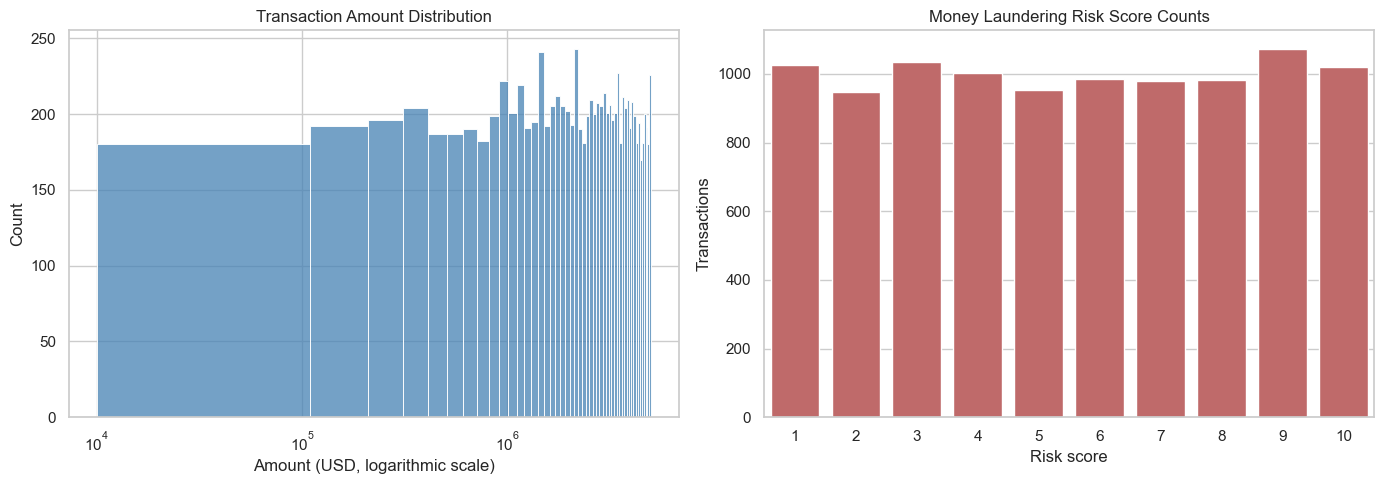

,count,mean,std,min,25%,50%,75%,max
Amount (USD),10000.0,2.501818e+06,1.424364e+06,10031.79673,1.279005e+06,2.501310e+06,3.722416e+06,4.999812e+06
Money Laundering Risk Score,10000.0,5.526400e+00,2.893603e+00,1.00000,3.000000e+00,6.000000e+00,8.000000e+00,1.000000e+01
Shell Companies Involved,10000.0,4.469400e+00,2.879773e+00,0.00000,2.000000e+00,4.000000e+00,7.000000e+00,9.000000e+00


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

amount_values = data["Amount (USD)"].dropna()
sns.histplot(amount_values, bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Transaction Amount Distribution")
axes[0].set_xlabel("Amount (USD)")
if not amount_values.empty and (amount_values > 0).all():
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Amount (USD, logarithmic scale)")

sns.countplot(data=data, x="Money Laundering Risk Score", ax=axes[1], color="indianred")
axes[1].set_title("Money Laundering Risk Score Counts")
axes[1].set_xlabel("Risk score")
axes[1].set_ylabel("Transactions")
plt.tight_layout()
plt.show()

display(data[["Amount (USD)", "Money Laundering Risk Score", "Shell Companies Involved"]].describe().T)

### 1.5.2 Categorical Variables

The plots show the most frequent values for selected categorical features. These frequency counts help identify dominant categories and high-cardinality fields that may need special encoding.

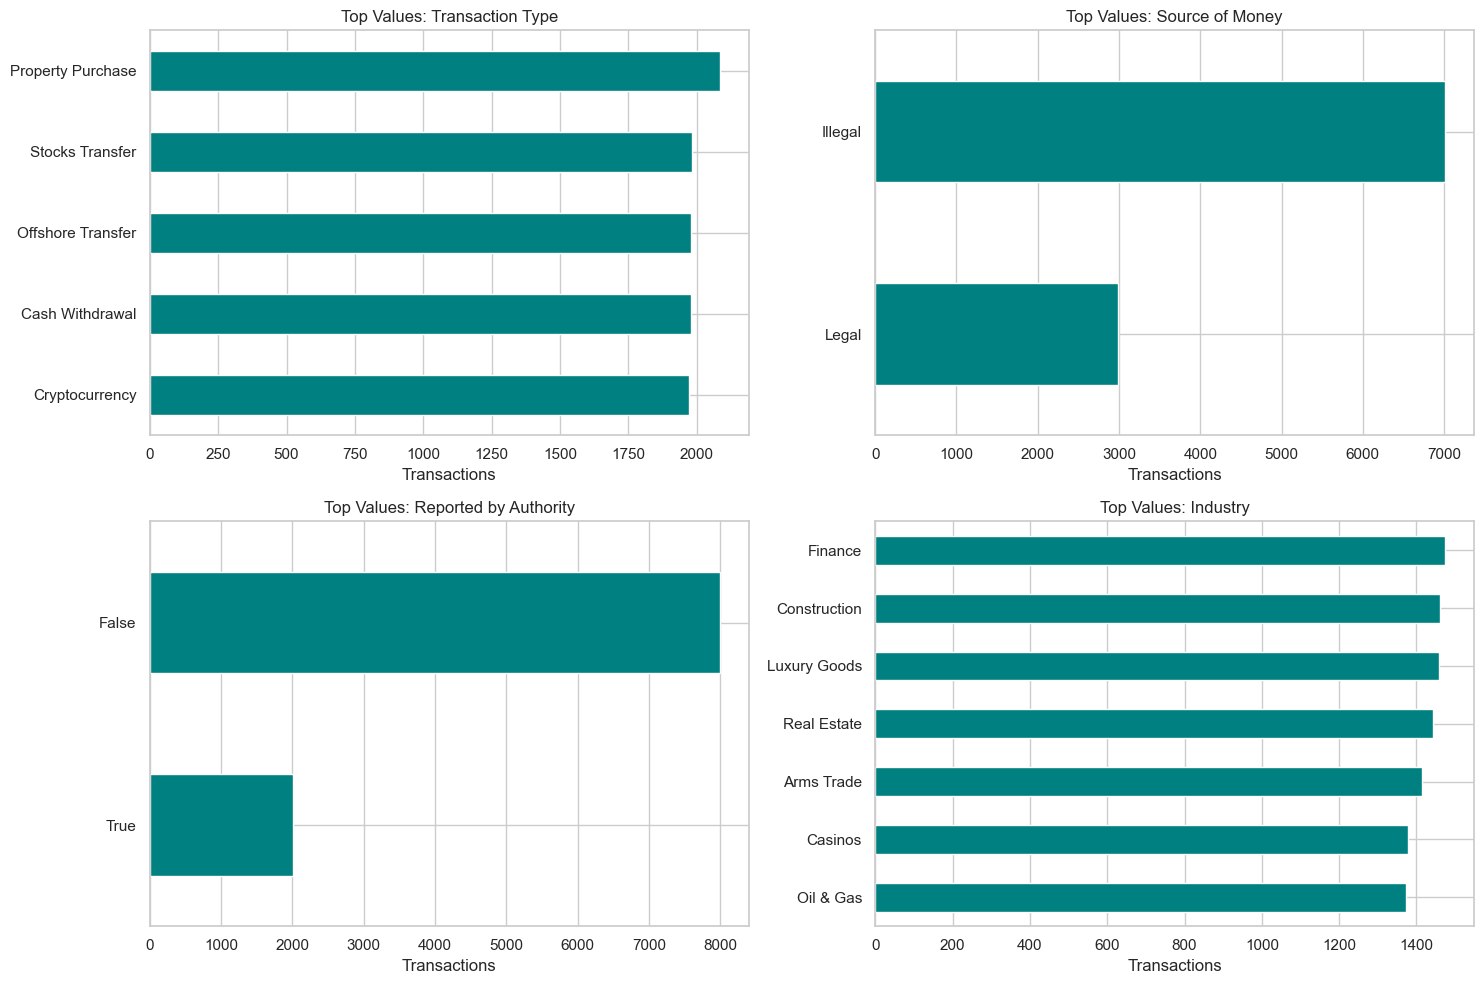

In [20]:
categorical_columns = [
    "Transaction Type",
    "Source of Money",
    "Reported by Authority",
    "Industry",
]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for column, axis in zip(categorical_columns, axes.flat):
    counts = data[column].astype("string").fillna("Missing").value_counts().head(10)
    counts.sort_values().plot(kind="barh", ax=axis, color="teal")
    axis.set_title(f"Top Values: {column}")
    axis.set_xlabel("Transactions")
    axis.set_ylabel("")

plt.tight_layout()
plt.show()

C:\Users\maria\AppData\Local\Temp\ipykernel_38460\3124759294.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='Country', order=data['Country'].value_counts().index, palette='viridis')


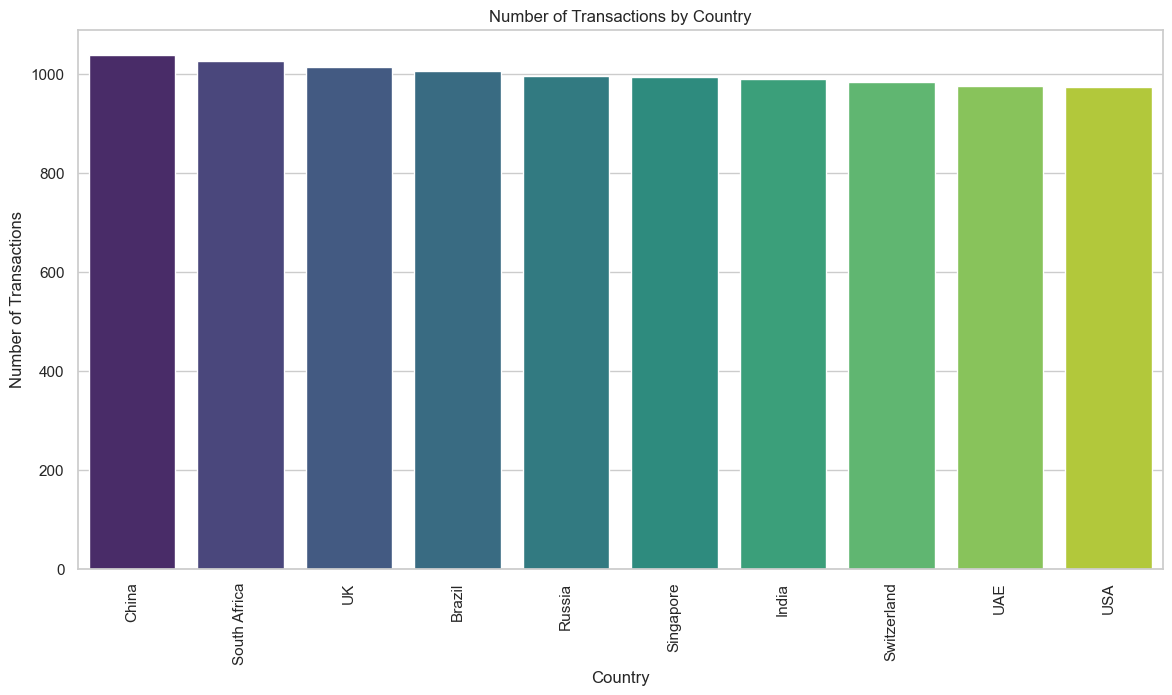

In [43]:
# Count of transactions by country
plt.figure(figsize=(14, 7))
sns.countplot(data=data, x='Country', order=data['Country'].value_counts().index, palette='viridis')
plt.title('Number of Transactions by Country')
plt.xlabel('Country')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=90)
plt.show()

## 1.6 Temporal Analysis

Transaction timestamps can reveal changes in activity over time. The chart aggregates transaction counts by month; gaps or peaks should be checked against the dataset's collection process before being interpreted as real-world events.

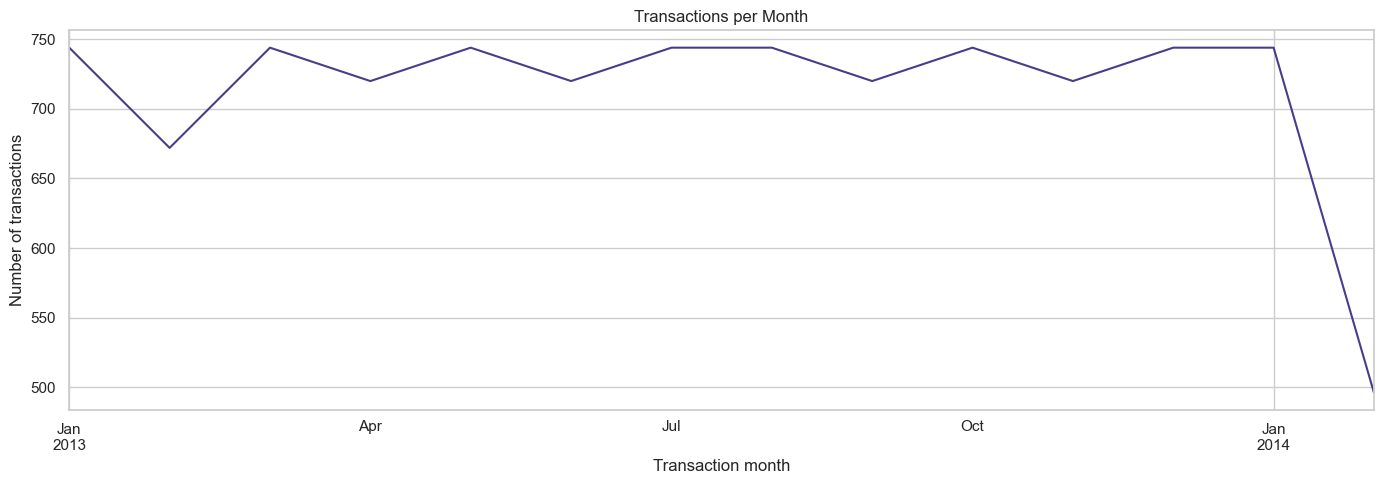

Rows with an invalid or missing transaction date: 0


In [21]:
dated_data = data.dropna(subset=["Date of Transaction"]).set_index("Date of Transaction")
monthly_counts = dated_data.resample("MS").size()

ax = monthly_counts.plot(figsize=(14, 5), color="darkslateblue")
ax.set_title("Transactions per Month")
ax.set_xlabel("Transaction month")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

print(f"Rows with an invalid or missing transaction date: {data['Date of Transaction'].isna().sum():,}")

## 1.7 Bivariate Analysis

### 1.7.1 Numeric Relationships

A rank-based correlation is included because monetary values can be skewed and relationships may not be linear. Correlation is descriptive and does not imply causation.

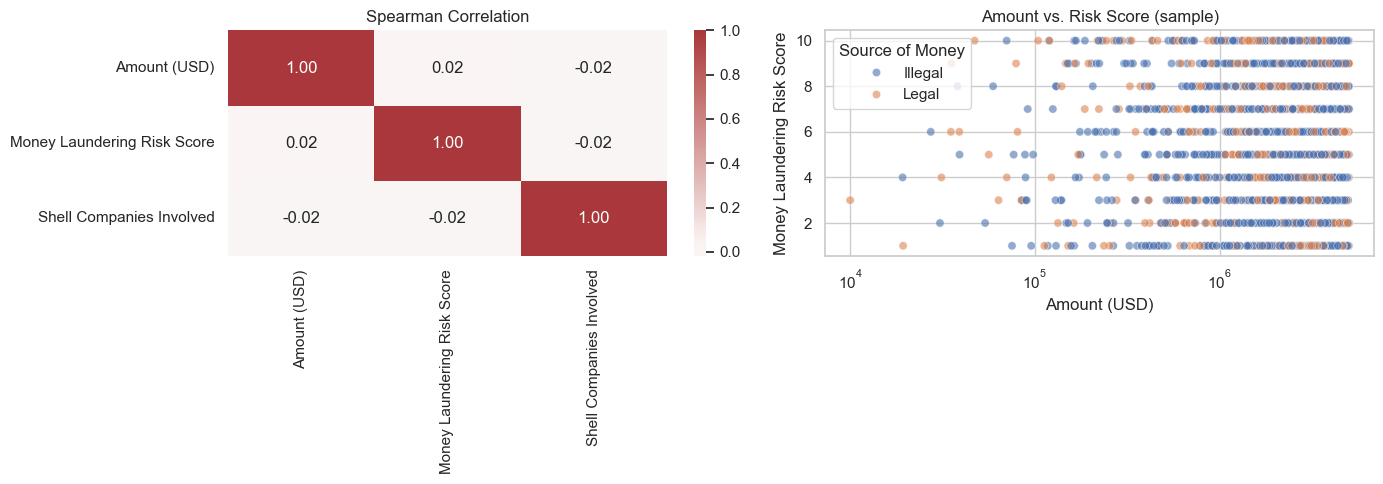

In [22]:
numeric_features = [
    "Amount (USD)",
    "Money Laundering Risk Score",
    "Shell Companies Involved",
]
correlation = data[numeric_features].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(correlation, annot=True, cmap="vlag", center=0, fmt=".2f", ax=axes[0])
axes[0].set_title("Spearman Correlation")

plot_sample = data[["Amount (USD)", "Money Laundering Risk Score", "Source of Money"]].dropna()
plot_sample = plot_sample.sample(min(2_000, len(plot_sample)), random_state=42)
sns.scatterplot(
    data=plot_sample,
    x="Amount (USD)",
    y="Money Laundering Risk Score",
    hue="Source of Money",
    alpha=0.6,
    ax=axes[1],
)
axes[1].set_title("Amount vs. Risk Score (sample)")
if not plot_sample.empty and (plot_sample["Amount (USD)"] > 0).all():
    axes[1].set_xscale("log")
plt.tight_layout()
plt.show()

### 1.7.2 Average Risk Score by Country

The charts compare the mean `Money Laundering Risk Score` by origin country (`Country`) and destination country (`Destination Country`). Transaction counts are shown beside each bar so the group sizes are visible. These are descriptive averages, not evidence that a country is inherently risky; the provenance audit later checks whether the dataset contains meaningful relationships.

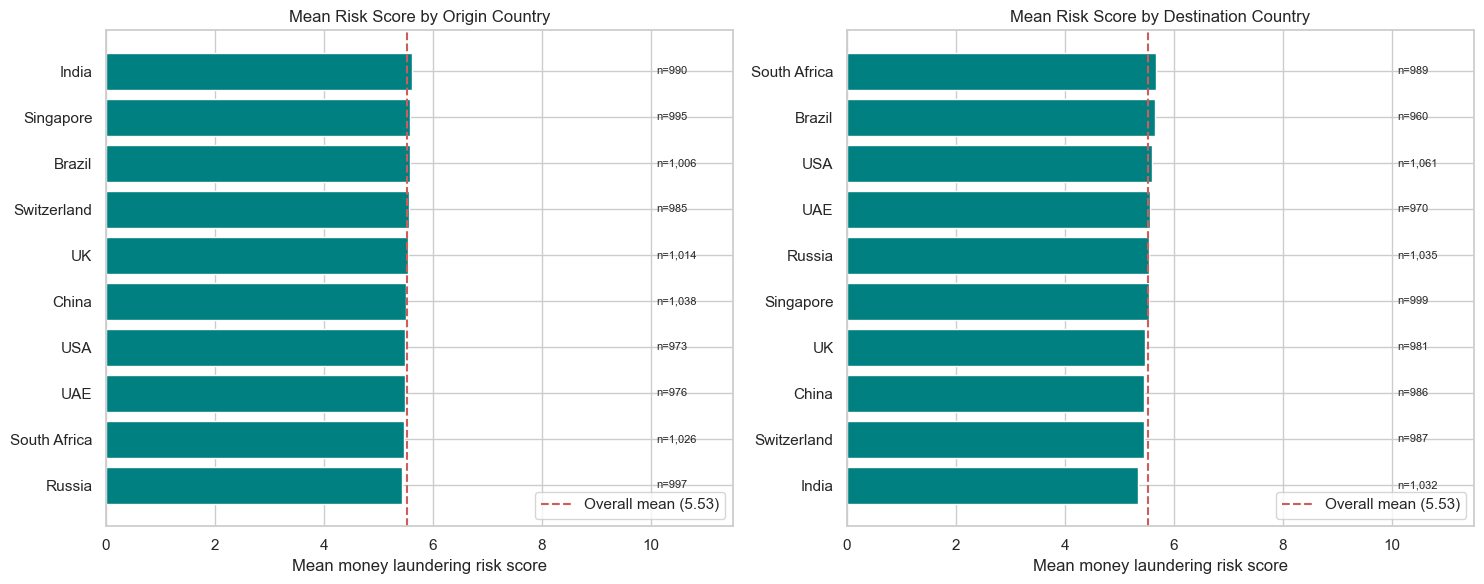

,Country role,Country,mean_score,transaction_count
15,Destination,South Africa,5.674,989
10,Destination,Brazil,5.655,960
19,Destination,USA,5.589,1061
17,Destination,UAE,5.555,970
13,Destination,Russia,5.550,1035
14,Destination,Singapore,5.536,999
18,Destination,UK,5.469,981
11,Destination,China,5.456,986
16,Destination,Switzerland,5.444,987
12,Destination,India,5.342,1032


In [44]:
country_columns = [
    ("Origin", "Country"),
    ("Destination", "Destination Country"),
]
country_summaries = []

for country_role, country_column in country_columns:
    country_summary = (
        data.groupby(country_column)["Money Laundering Risk Score"]
        .agg(mean_score="mean", transaction_count="size")
        .reset_index()
        .rename(columns={country_column: "Country"})
    )
    country_summary.insert(0, "Country role", country_role)
    country_summaries.append(country_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
overall_mean_score = data["Money Laundering Risk Score"].mean()

for axis, (country_role, country_summary) in zip(axes, zip(
    ["Origin", "Destination"], country_summaries
)):
    ordered_summary = country_summary.sort_values("mean_score", ascending=True)
    axis.barh(ordered_summary["Country"], ordered_summary["mean_score"], color="teal")
    axis.axvline(
        overall_mean_score,
        color="indianred",
        linestyle="--",
        label=f"Overall mean ({overall_mean_score:.2f})",
    )
    for position, (_, row) in enumerate(ordered_summary.iterrows()):
        axis.text(10.1, position, f"n={row['transaction_count']:,}", va="center", fontsize=8)
    axis.set_title(f"Mean Risk Score by {country_role} Country")
    axis.set_xlabel("Mean money laundering risk score")
    axis.set_ylabel("")
    axis.set_xlim(0, 11.5)
    axis.legend(loc="lower right")

plt.tight_layout()
plt.show()

display(pd.concat(country_summaries, ignore_index=True)
        .sort_values(["Country role", "mean_score"], ascending=[True, False])
        .round({"mean_score": 3}))

## 1.8 Feature Engineering

The following derived fields are examples for exploration, not a final modeling dataset. The original columns remain unchanged, and any derived amount transformation is created only for non-negative values.

In [23]:
eda_features = data.copy()
transaction_dates = eda_features["Date of Transaction"]
eda_features["Transaction Year"] = transaction_dates.dt.year
eda_features["Transaction Month"] = transaction_dates.dt.month
eda_features["Transaction Day of Week"] = transaction_dates.dt.dayofweek
eda_features["Is Cross-Border"] = (
    eda_features["Country"].str.strip().str.casefold()
    != eda_features["Destination Country"].str.strip().str.casefold()
)

eda_features["Amount Log1p"] = np.nan
non_negative_amounts = eda_features["Amount (USD)"].ge(0)
eda_features.loc[non_negative_amounts, "Amount Log1p"] = np.log1p(
    eda_features.loc[non_negative_amounts, "Amount (USD)"]
)

display(eda_features[[
    "Date of Transaction",
    "Transaction Year",
    "Transaction Month",
    "Transaction Day of Week",
    "Country",
    "Destination Country",
    "Is Cross-Border",
    "Amount (USD)",
    "Amount Log1p",
]].head())
print(f"Negative amount records: {data['Amount (USD)'].lt(0).sum():,}")

,Date of Transaction,Transaction Year,Transaction Month,Transaction Day of Week,Country,Destination Country,Is Cross-Border,Amount (USD),Amount Log1p
0,2013-01-01 00:00:00,2013,1,1,Brazil,USA,True,3.267530e+06,14.999545
1,2013-01-01 01:00:00,2013,1,1,China,South Africa,True,4.965767e+06,15.418078
2,2013-01-01 02:00:00,2013,1,1,UK,Switzerland,True,9.416750e+04,11.452841
3,2013-01-01 03:00:00,2013,1,1,UAE,Russia,True,3.864201e+05,12.864683
4,2013-01-01 04:00:00,2013,1,1,South Africa,USA,True,6.433784e+05,13.374490


Negative amount records: 0


## 1.10 Provenance Audit

The sections above describe the dataset as it presents itself. This section tests whether that presentation can be taken at face value, which is the question left open by the final bullet in the preprocessing recommendations at 1.16.1.

The distinction matters for the project and not only for the report. If the file was produced by drawing each column independently from a fixed distribution, then the associations examined in 1.7 are sampling noise, the derived fields in 1.8 carry no information, and the preprocessing choices described in 1.16.1 are decisions about an empty signal. None of this is visible in a conventional exploratory pass, because a generated file looks tidy: no missing values, no duplicates, well-behaved ranges, a clean identifier column.

Five hypotheses are tested below, each with its own section. Note the direction of the evidence. The nulls are statements about a generated file, so **failing to reject a null is the unfavourable outcome** — it means the column behaves like a random draw rather than a record of events.

| Section | Null hypothesis | Consequence if not rejected |
|---|---|---|
| 1.10.1 | `Date of Transaction` increments mechanically | The temporal analysis in 1.6 describes the generator, not behaviour |
| 1.10.2 | Columns are uniform draws | No distributional shape to model |
| 1.10.3| Amounts do not follow Benford's law | Amounts were not produced by a financial process |
| 1.10.4 | `Person Involved` has no persistent attributes | The field is a label, not an entity |
| 1.10.5 | All column pairs are independent | The bivariate analysis in 1.7 has nothing to find |

Section 1.10.6 collects the outcomes into a single table.

### 1.10.1 Timestamp Regularity

Observation times carry structure when they record real events: activity concentrates in business hours, drops at weekends, and clusters around period ends. A timestamp produced by incrementing a counter has none of that, and the symptom is diagnostic — the interval between consecutive records is constant.

The test sorts the records by date and examines the distribution of gaps. Under a real process these are irregular, with many near zero and some long. The monthly, hourly, and weekday charts are reproduced alongside so they can be read in light of the result.

Date range          : 2013-01-01 00:00:00  to  2014-02-21 15:00:00
Unique timestamps   : 10,000 of 10,000 records
Span in hours       : 9,999
Distinct gap values : 1

Most frequent gaps between consecutive records (hours):


,Records
Date of Transaction,
1.0,9999


,Gap (hours)
count,9999.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0


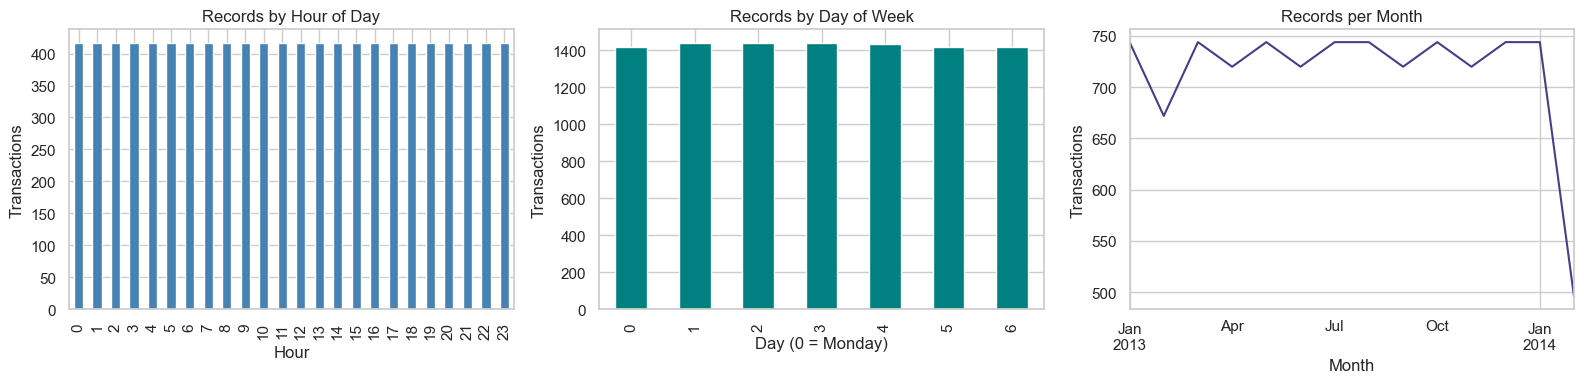


Every interval is exactly 1 hour(s). The column advances by a fixed step for each successive record, which is the behaviour of a row counter formatted as a datetime rather than a record of when anything occurred.
The three charts above are therefore properties of the calendar and of the length of the generated sequence. They should not be read as activity patterns.


In [37]:

# Collects the outcome of every test in this audit; section 1.15 assembles the summary.
audit_results = []

def record_outcome(section, hypothesis, rejected, evidence):
    audit_results.append({
        "Section": section,
        "Null hypothesis": hypothesis,
        "Rejected": "Yes" if rejected else "No",
        "Evidence": evidence,
    })

ordered_dates = data["Date of Transaction"].sort_values()
gap_hours = ordered_dates.diff().dropna().dt.total_seconds() / 3600

print(f"Date range          : {ordered_dates.min()}  to  {ordered_dates.max()}")
print(f"Unique timestamps   : {ordered_dates.nunique():,} of {len(ordered_dates):,} records")
print(f"Span in hours       : {(ordered_dates.max() - ordered_dates.min()).total_seconds() / 3600:,.0f}")
print(f"Distinct gap values : {gap_hours.nunique():,}")

print("\nMost frequent gaps between consecutive records (hours):")
display(gap_hours.value_counts().head().to_frame("Records"))
display(gap_hours.describe().to_frame("Gap (hours)"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
data["Date of Transaction"].dt.hour.value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Records by Hour of Day")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Transactions")

data["Date of Transaction"].dt.dayofweek.value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color="teal")
axes[1].set_title("Records by Day of Week")
axes[1].set_xlabel("Day (0 = Monday)")
axes[1].set_ylabel("Transactions")

data.set_index("Date of Transaction").resample("MS").size().plot(
    ax=axes[2], color="darkslateblue")
axes[2].set_title("Records per Month")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Transactions")

plt.tight_layout()
plt.show()

mechanical = gap_hours.nunique() == 1
if mechanical:
    print(f"\nEvery interval is exactly {gap_hours.iloc[0]:g} hour(s). The column advances by a "
          "fixed step for each successive record, which is the behaviour of a row counter "
          "formatted as a datetime rather than a record of when anything occurred.")
    print("The three charts above are therefore properties of the calendar and of the length "
          "of the generated sequence. They should not be read as activity patterns.")
else:
    print(f"\nIntervals take {gap_hours.nunique():,} distinct values, which is consistent with "
          "timestamps recording distinct events.")

record_outcome("1.10.1", "Date of Transaction increments mechanically", not mechanical,
               f"{gap_hours.nunique():,} distinct interval values between consecutive records")



### 1.10.2 Distributional Tests

Section 1.5 presented the univariate distributions without asking what shape would be expected. This section supplies the reference point.

Transaction amounts generated by economic activity are strongly right-skewed: many small payments and progressively fewer large ones. A flat distribution bounded by a floor and a ceiling is instead the signature of a pseudo-random draw. The same reasoning applies to the ordinal and categorical fields, where an even spread across every level is unusual in observed data and typical of generated data.

Two tests are applied. The Kolmogorov-Smirnov test compares `Amount (USD)` against a continuous uniform distribution over its own observed range. A chi-square goodness-of-fit test compares each discrete and categorical column against an even spread across its levels. A **high p-value fails to reject uniformity** and is the unfavourable outcome.

The moment comparison that follows is a second, independent check: it places the observed mean and standard deviation beside the values a uniform distribution over the same range would produce.


,Column,Test,Statistic,p-value,Consistent with uniform
0,Amount (USD),Kolmogorov-Smirnov,0.009,0.4198,Yes
1,Money Laundering Risk Score,Chi-square goodness of fit,13.776,0.1305,Yes
2,Shell Companies Involved,Chi-square goodness of fit,4.968,0.8371,Yes
3,Country,Chi-square goodness of fit,4.016,0.9104,Yes
4,Destination Country,Chi-square goodness of fit,9.318,0.4085,Yes
5,Transaction Type,Chi-square goodness of fit,4.649,0.3252,Yes
6,Industry,Chi-square goodness of fit,7.245,0.2988,Yes
7,Tax Haven Country,Chi-square goodness of fit,5.774,0.3288,Yes


Observed moments compared with a uniform distribution over the same range:


,Column,Observed mean,Uniform mean,Observed std,Uniform std,Mean deviation %,Std deviation %
0,Amount (USD),2501817.665,2504922.103,1424364.283,1440425.590,0.124,1.115
1,Money Laundering Risk Score,5.526,5.500,2.894,2.872,0.480,0.742
2,Shell Companies Involved,4.469,4.500,2.880,2.872,0.680,0.261


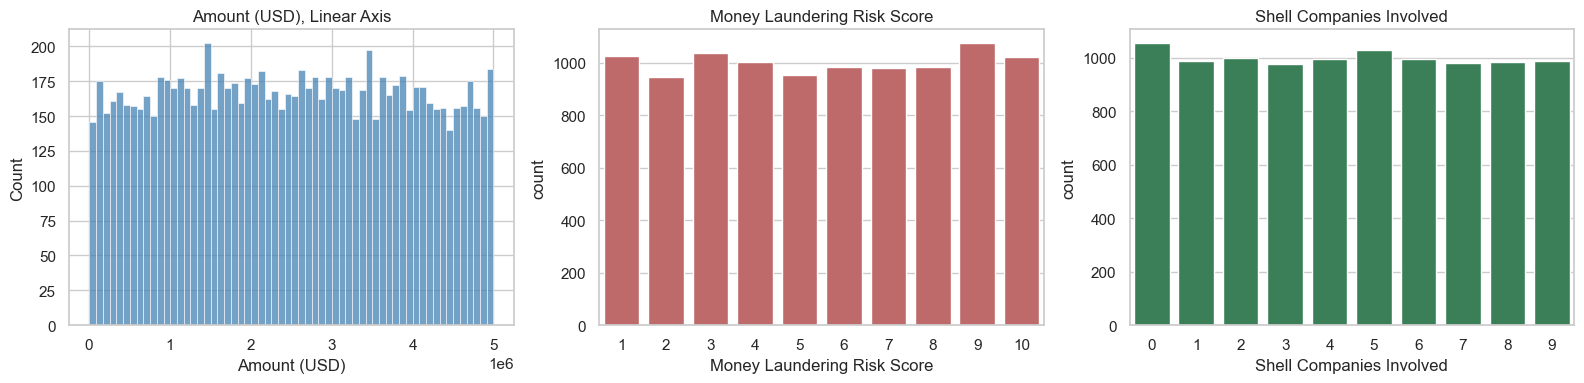


8 of 8 columns are indistinguishable from a uniform distribution at alpha = 0.05.
Note that 1.5 plotted the amount on a logarithmic axis, which gives a flat distribution the appearance of a left-skewed one. The linear axis above shows the underlying shape.


In [38]:
ALPHA = 0.05
test_rows = []

amounts = data["Amount (USD)"].dropna()
ks_result = stats.kstest(amounts, "uniform", args=(amounts.min(), amounts.max() - amounts.min()))
test_rows.append(["Amount (USD)", "Kolmogorov-Smirnov", ks_result.statistic, ks_result.pvalue])

discrete_columns = [
    "Money Laundering Risk Score",
    "Shell Companies Involved",
    "Country",
    "Destination Country",
    "Transaction Type",
    "Industry",
    "Tax Haven Country",
]
for column in discrete_columns:
    observed = data[column].value_counts().values
    chi_result = stats.chisquare(observed)
    test_rows.append([column, "Chi-square goodness of fit", chi_result.statistic, chi_result.pvalue])

uniformity = pd.DataFrame(test_rows, columns=["Column", "Test", "Statistic", "p-value"])
uniformity["Consistent with uniform"] = np.where(uniformity["p-value"] > ALPHA, "Yes", "No")
display(uniformity.round({"Statistic": 3, "p-value": 4}))

moment_rows = []
low, high = amounts.min(), amounts.max()
moment_rows.append(["Amount (USD)", amounts.mean(), (low + high) / 2,
                    amounts.std(), (high - low) / np.sqrt(12)])
for column in ["Money Laundering Risk Score", "Shell Companies Involved"]:
    series = data[column]
    levels = series.nunique()
    moment_rows.append([column, series.mean(), (series.min() + series.max()) / 2,
                        series.std(), np.sqrt((levels ** 2 - 1) / 12)])

moments = pd.DataFrame(moment_rows, columns=["Column", "Observed mean", "Uniform mean",
                                             "Observed std", "Uniform std"])
moments["Mean deviation %"] = ((moments["Observed mean"] - moments["Uniform mean"]).abs()
                               / moments["Uniform mean"] * 100)
moments["Std deviation %"] = ((moments["Observed std"] - moments["Uniform std"]).abs()
                              / moments["Uniform std"] * 100)
print("Observed moments compared with a uniform distribution over the same range:")
display(moments.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(amounts, bins=60, ax=axes[0], color="steelblue")
axes[0].set_title("Amount (USD), Linear Axis")
axes[0].set_xlabel("Amount (USD)")
sns.countplot(data=data, x="Money Laundering Risk Score", ax=axes[1], color="indianred")
axes[1].set_title("Money Laundering Risk Score")
sns.countplot(data=data, x="Shell Companies Involved", ax=axes[2], color="seagreen")
axes[2].set_title("Shell Companies Involved")
plt.tight_layout()
plt.show()

n_uniform = int((uniformity["p-value"] > ALPHA).sum())
print(f"\n{n_uniform} of {len(uniformity)} columns are indistinguishable from a uniform "
      f"distribution at alpha = {ALPHA}.")
print("Note that 1.5 plotted the amount on a logarithmic axis, which gives a flat distribution "
      "the appearance of a left-skewed one. The linear axis above shows the underlying shape.")

record_outcome("1.11", "Columns are uniform draws", n_uniform < len(uniformity) / 2,
               f"{n_uniform} of {len(uniformity)} columns consistent with uniform")



### 1.10.3 Leading-Digit Analysis

Benford's law describes the leading digit of quantities produced by multiplicative processes spanning several orders of magnitude. Roughly thirty per cent of such values begin with 1 and under five per cent begin with 9. Real monetary figures follow it closely enough that tax authorities and forensic accountants treat departures from it as an indicator worth investigating.

A uniform draw over a fixed interval cannot satisfy the law, and the way it fails is informative. When the interval spans from roughly ten thousand to five million, the great majority of the probability mass falls in the highest decade, so leading digits 1 to 4 are heavily over-represented and digits 5 to 9 are close to absent. That specific profile is difficult to produce by any means other than a bounded uniform draw.

The chi-square test below compares the observed leading-digit counts against the Benford expectation.


,Leading digit,Observed,Observed %,Benford %,Expected
0,1,2280,22.80,30.10,3010.30
1,2,2268,22.68,17.61,1760.91
2,3,2240,22.40,12.49,1249.39
3,4,2142,21.42,9.69,969.10
4,5,204,2.04,7.92,791.81
5,6,200,2.00,6.69,669.47
6,7,210,2.10,5.80,579.92
7,8,216,2.16,5.12,511.53
8,9,240,2.40,4.58,457.57


Chi-square = 3,803.9    p-value = 0


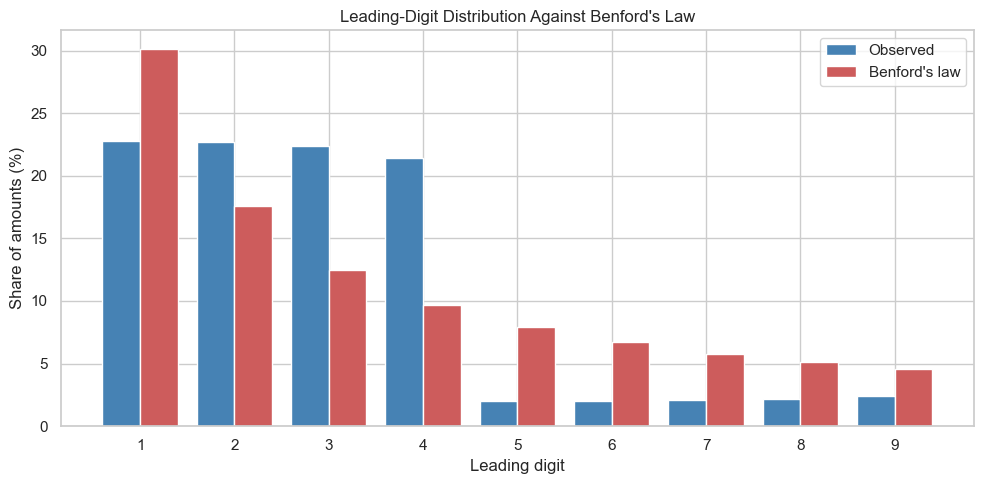


Digits 1 to 4 account for 89.3% of amounts; digits 5 to 9 for 10.7%.
The observed profile is flat across the first four digits and then falls sharply, which is what a uniform draw over a range spanning several decades produces. It is not consistent with amounts arising from an economic process.


In [39]:
leading_digit = (data["Amount (USD)"]
                 .dropna()
                 .abs()
                 .astype(str)
                 .str.replace(r"[^1-9]", "", regex=True)
                 .str[0]
                 .astype(int))

digits = np.arange(1, 10)
benford_share = np.log10(1 + 1 / digits)
observed_counts = leading_digit.value_counts().reindex(digits, fill_value=0).values
expected_counts = benford_share * observed_counts.sum()

benford_test = stats.chisquare(observed_counts, expected_counts)

benford_table = pd.DataFrame({
    "Leading digit": digits,
    "Observed": observed_counts,
    "Observed %": observed_counts / observed_counts.sum() * 100,
    "Benford %": benford_share * 100,
    "Expected": expected_counts,
})
display(benford_table.round(2))
print(f"Chi-square = {benford_test.statistic:,.1f}    p-value = {benford_test.pvalue:.3g}")

fig, ax = plt.subplots(figsize=(10, 5))
width = 0.4
ax.bar(digits - width / 2, observed_counts / observed_counts.sum() * 100, width,
       label="Observed", color="steelblue")
ax.bar(digits + width / 2, benford_share * 100, width,
       label="Benford's law", color="indianred")
ax.set_xticks(digits)
ax.set_xlabel("Leading digit")
ax.set_ylabel("Share of amounts (%)")
ax.set_title("Leading-Digit Distribution Against Benford's Law")
ax.legend()
plt.tight_layout()
plt.show()

follows_benford = benford_test.pvalue > ALPHA
top_four = observed_counts[:4].sum() / observed_counts.sum() * 100
bottom_five = observed_counts[4:].sum() / observed_counts.sum() * 100
print(f"\nDigits 1 to 4 account for {top_four:.1f}% of amounts; digits 5 to 9 for {bottom_five:.1f}%.")
if not follows_benford:
    print("The observed profile is flat across the first four digits and then falls sharply, "
          "which is what a uniform draw over a range spanning several decades produces. It is "
          "not consistent with amounts arising from an economic process.")

record_outcome("1.12", "Amounts do not follow Benford's law", follows_benford,
               f"chi-square = {benford_test.statistic:,.0f}, p = {benford_test.pvalue:.3g}")


### 1.10.4 Entity Consistency

Section 1.16.1 recommends treating `Person Involved` as an entity identifier and using it for grouped splitting only when the field represents a persistent real entity. This section tests that assumption.

An entity has attributes that persist across its records. A person appearing several times is resident in one country, works in one industry, and banks at one or a small number of institutions; their transactions vary while their identity does not. If instead every field was drawn independently for each row, a person's country is re-drawn each time they appear, and the identifier distinguishes rows without describing anyone.

The test below restricts attention to people appearing more than once and counts how many distinct values each attribute takes for them. The comparison is against the number expected if the attribute were re-drawn on every appearance, computed from the number of levels and the number of appearances. A ratio near one indicates re-drawing; a ratio well below one indicates persistence.

The consequence is structural rather than statistical. Without persistent attributes there is no entity to aggregate over, no coherent unit to group a train-test split on, and no way to assemble related records into a case.

Distinct people              : 6,320
People appearing more than once: 2,655
Records involving them       : 6,335
Highest number of appearances: 7


,Attribute,Levels,Observed distinct per person,Expected if re-drawn,Ratio,People with a single value (%)
0,Country,10,2.209,2.204,1.002,7.043
1,Industry,7,2.124,2.129,0.998,11.186
2,Destination Country,10,2.202,2.204,0.999,6.742
3,Financial Institution,499,2.381,2.382,1.000,0.226
4,Tax Haven Country,6,2.089,2.089,1.000,12.618
5,Source of Money,2,1.481,1.584,0.935,51.902


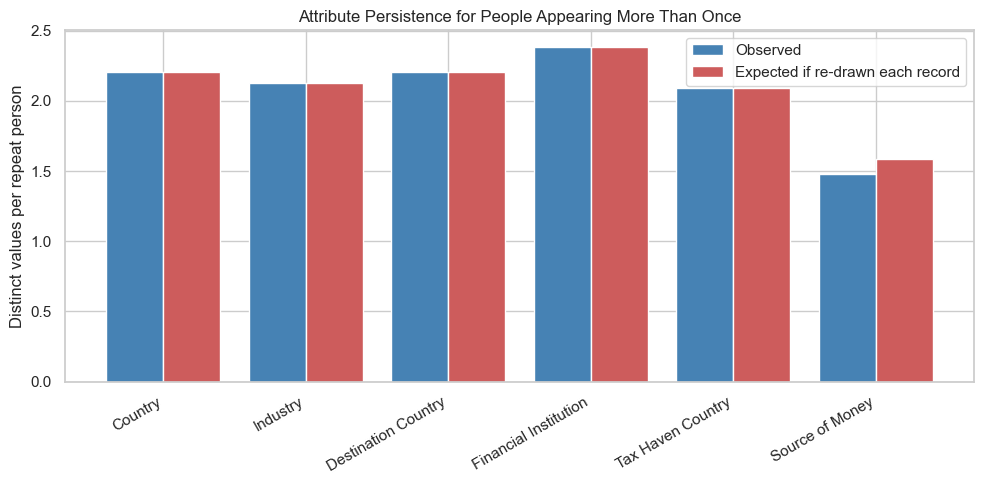


Mean ratio of observed to expected distinct values: 0.989
Attributes are re-drawn on each appearance, so the identifier labels rows without describing a person. The grouped-splitting recommendation in 1.16.1 has no unit to group on, and records cannot be assembled into cases.


In [40]:
appearance_counts = data["Person Involved"].value_counts()
repeat_ids = appearance_counts[appearance_counts > 1].index
repeat_records = data[data["Person Involved"].isin(repeat_ids)]

print(f"Distinct people              : {data['Person Involved'].nunique():,}")
print(f"People appearing more than once: {len(repeat_ids):,}")
print(f"Records involving them       : {len(repeat_records):,}")
print(f"Highest number of appearances: {appearance_counts.max():,}")

consistency_rows = []
for attribute in ["Country", "Industry", "Destination Country",
                  "Financial Institution", "Tax Haven Country", "Source of Money"]:
    observed_distinct = repeat_records.groupby("Person Involved")[attribute].nunique()
    n_levels = data[attribute].nunique()
    expected_distinct = (repeat_records.groupby("Person Involved").size()
                         .apply(lambda k: n_levels * (1 - (1 - 1 / n_levels) ** k))
                         .mean())
    consistency_rows.append([
        attribute, n_levels, observed_distinct.mean(), expected_distinct,
        observed_distinct.mean() / expected_distinct,
        (observed_distinct == 1).mean() * 100,
    ])

consistency = pd.DataFrame(consistency_rows, columns=[
    "Attribute", "Levels", "Observed distinct per person",
    "Expected if re-drawn", "Ratio", "People with a single value (%)"])
display(consistency.round(3))

fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(consistency))
width = 0.4
ax.bar(positions - width / 2, consistency["Observed distinct per person"], width,
       label="Observed", color="steelblue")
ax.bar(positions + width / 2, consistency["Expected if re-drawn"], width,
       label="Expected if re-drawn each record", color="indianred")
ax.set_xticks(positions)
ax.set_xticklabels(consistency["Attribute"], rotation=30, ha="right")
ax.set_ylabel("Distinct values per repeat person")
ax.set_title("Attribute Persistence for People Appearing More Than Once")
ax.legend()
plt.tight_layout()
plt.show()

mean_ratio = consistency["Ratio"].mean()
not_an_entity = mean_ratio > 0.90
print(f"\nMean ratio of observed to expected distinct values: {mean_ratio:.3f}")
if not_an_entity:
    print("Attributes are re-drawn on each appearance, so the identifier labels rows without "
          "describing a person. The grouped-splitting recommendation in 1.16.1 has no unit to "
          "group on, and records cannot be assembled into cases.")

record_outcome("1.13", "Person Involved has no persistent attributes", not not_an_entity,
               f"mean observed-to-expected ratio = {mean_ratio:.3f}")


### 1.10.5 Independence Across Columns

Section 1.7 examined three numeric columns with a rank correlation. This section widens that to every pair of columns and changes the question: rather than asking which pairs are related, it asks whether any pair is.

Cramer's V measures association between two categorical variables on a scale from zero to one, where zero is independence. It is used here because most of the columns are categorical and because it is defined for tables of any size. Spearman's coefficient covers the numeric columns, as in 1.7.

The reference point matters for reading the result. With ten thousand records, sampling noise alone produces associations of roughly 0.01 to 0.03 between genuinely independent columns. Values in that band are not weak relationships; they are the absence of a relationship.


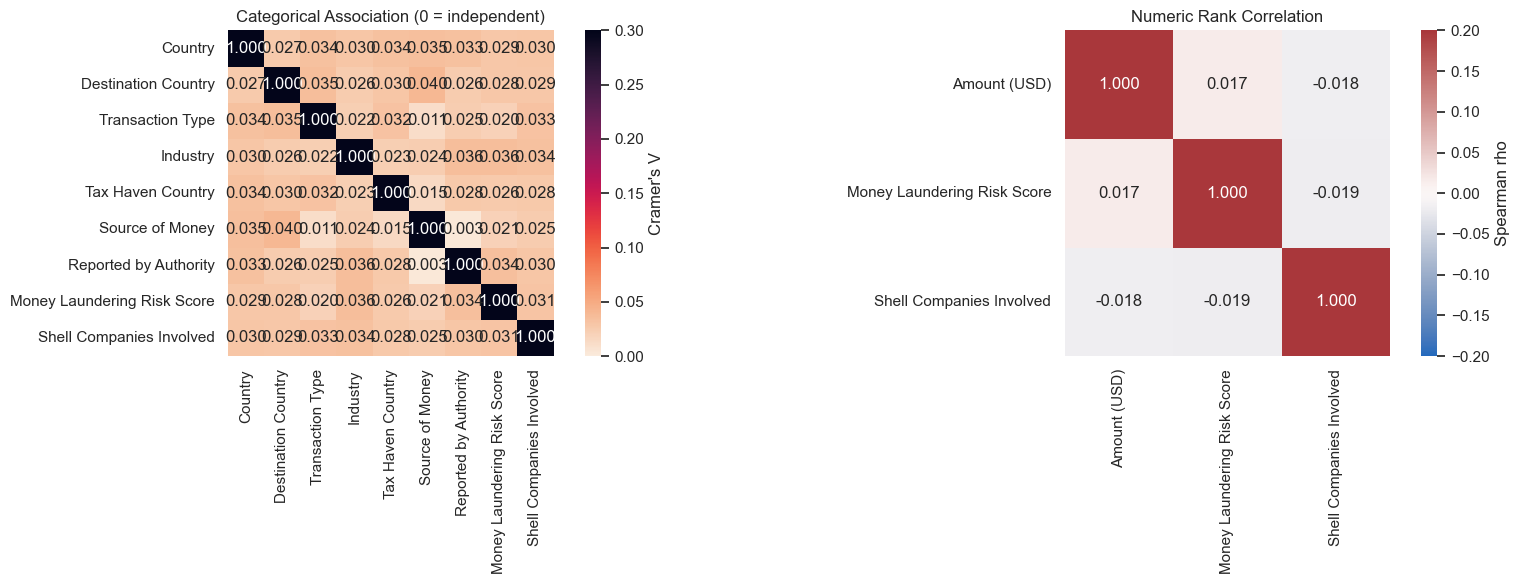

Cramer's V across 36 distinct column pairs:
  maximum : 0.0402
  mean    : 0.0279
  median  : 0.0293

Strongest associations observed:


Cramer's V
Destination Country Source of Money                  0.0402
Industry            Money Laundering Risk Score      0.0360
                    Reported by Authority            0.0358
Destination Country Transaction Type                 0.0355
Source of Money     Country                          0.0347

Largest absolute Spearman coefficient off the diagonal: 0.0191

No pair exceeds what sampling noise produces at this sample size, so the bivariate analysis in 1.7 has no relationship available to describe.


In [41]:
def cramers_v(first, second):
    contingency = pd.crosstab(first, second)
    chi2 = stats.chi2_contingency(contingency, correction=False)[0]
    n = contingency.values.sum()
    rows, cols = contingency.shape
    return np.sqrt((chi2 / n) / max(min(rows - 1, cols - 1), 1))

association_columns = [
    "Country", "Destination Country", "Transaction Type", "Industry",
    "Tax Haven Country", "Source of Money", "Reported by Authority",
    "Money Laundering Risk Score", "Shell Companies Involved",
]

association = pd.DataFrame(np.eye(len(association_columns)),
                           index=association_columns, columns=association_columns)
for i, first in enumerate(association_columns):
    for second in association_columns[i + 1:]:
        value = cramers_v(data[first], data[second])
        association.loc[first, second] = value
        association.loc[second, first] = value

numeric_columns = ["Amount (USD)", "Money Laundering Risk Score", "Shell Companies Involved"]
rank_correlation = data[numeric_columns].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(association, annot=True, fmt=".3f", cmap="rocket_r", vmin=0, vmax=0.30,
            square=True, ax=axes[0], cbar_kws={"label": "Cramer's V"})
axes[0].set_title("Categorical Association (0 = independent)")
sns.heatmap(rank_correlation, annot=True, fmt=".3f", cmap="vlag", center=0,
            vmin=-0.20, vmax=0.20, square=True, ax=axes[1],
            cbar_kws={"label": "Spearman rho"})
axes[1].set_title("Numeric Rank Correlation")
plt.tight_layout()
plt.show()

off_diagonal = association.where(~np.eye(len(association), dtype=bool)).stack()
pair_count = len(off_diagonal) // 2
print(f"Cramer's V across {pair_count} distinct column pairs:")
print(f"  maximum : {off_diagonal.max():.4f}")
print(f"  mean    : {off_diagonal.mean():.4f}")
print(f"  median  : {off_diagonal.median():.4f}")
print("\nStrongest associations observed:")
display(off_diagonal.sort_values(ascending=False).iloc[::2].head().to_frame("Cramer's V").round(4))

max_rho = rank_correlation.where(~np.eye(len(rank_correlation), dtype=bool)).abs().max().max()
print(f"Largest absolute Spearman coefficient off the diagonal: {max_rho:.4f}")

association_present = off_diagonal.max() > 0.10
if not association_present:
    print("\nNo pair exceeds what sampling noise produces at this sample size, so the "
          "bivariate analysis in 1.7 has no relationship available to describe.")

record_outcome("1.14", "All column pairs are independent", association_present,
               f"maximum Cramer's V = {off_diagonal.max():.4f}, mean = {off_diagonal.mean():.4f}")



### 1.10.6 Audit Summary

The table below is assembled from the outcomes recorded by the preceding sections, so it cannot diverge from what those cells produced. The structural limitations that follow it are properties of the schema rather than results of a test, and additional records would not remove them.


In [42]:
summary_table = pd.DataFrame(audit_results)
display(summary_table)

rejected = int((summary_table["Rejected"] == "Yes").sum())
total = len(summary_table)
print(f"{rejected} of {total} null hypotheses rejected.\n")

structural = pd.DataFrame([
    ["Payer and payee identifiers", "Not present",
     "Movement is recorded as Country to Destination Country only, so records cannot be chained."],
    ["Transaction network", "Not constructible",
     "Without counterparty identifiers there is no graph to traverse."],
    ["Verified laundering label", "Not present",
     "Source of Money and the risk score are unvalidated fields, not confirmed outcomes."],
    ["Case or scheme identifier", "Not present",
     "No field groups related records, so cases cannot be reconstructed."],
    ["Entity-level aggregation", "Not available",
     "Person attributes are not persistent, as shown in 1.13."],
    ["Grouped train-test split", "Not available",
     "Requires a persistent entity to group on."],
    ["Chronological train-test split", "Not meaningful",
     "The timestamp advances mechanically, as shown in 1.10.1, so a date cut-off is an arbitrary row cut."],
], columns=["Capability", "Status", "Basis"])
print("Structural limitations of the schema:")
display(structural)

if rejected == 0:
    print("\nEvery null hypothesis survived. The dataset is consistent throughout with "
          "independent draws from fixed distributions: the timestamp advances mechanically, "
          "the columns are uniformly distributed, the amounts do not follow the leading-digit "
          "pattern of financial data, the person identifier carries no persistent attributes, "
          "and no pair of columns is associated beyond sampling noise.")
    print("\nThis answers the provenance question raised in the preprocessing recommendations at 1.16.1: "
          "the file is generated. With no column related to any other, there is nothing for a "
          "supervised model to learn. It remains usable as a clean and fast backend for "
          "demonstrating retrieval and tool calls, provided no component of the system asserts "
          "that a transaction is illicit on the basis of these fields.")
    print("\nReported as a negative result this is a legitimate finding. Validating a dataset "
          "before building on it, and auditing an unexplained risk score, are both standard "
          "steps in anti-money-laundering practice.")
else:
    print("\nAt least one null hypothesis was rejected. Review the corresponding sections "
          "before drawing a conclusion about provenance.")

,Section,Null hypothesis,Rejected,Evidence
0,1.10.1,Date of Transaction increments mechanically,No,1 distinct interval values between consecutive...
1,1.11,Columns are uniform draws,No,8 of 8 columns consistent with uniform
2,1.12,Amounts do not follow Benford's law,No,"chi-square = 3,804, p = 0"
3,1.13,Person Involved has no persistent attributes,No,mean observed-to-expected ratio = 0.989
4,1.14,All column pairs are independent,No,"maximum Cramer's V = 0.0402, mean = 0.0279"


0 of 5 null hypotheses rejected.

Structural limitations of the schema:


,Capability,Status,Basis
0,Payer and payee identifiers,Not present,Movement is recorded as Country to Destination...
1,Transaction network,Not constructible,Without counterparty identifiers there is no g...
2,Verified laundering label,Not present,Source of Money and the risk score are unvalid...
3,Case or scheme identifier,Not present,"No field groups related records, so cases cann..."
4,Entity-level aggregation,Not available,"Person attributes are not persistent, as shown..."
5,Grouped train-test split,Not available,Requires a persistent entity to group on.
6,Chronological train-test split,Not meaningful,"The timestamp advances mechanically, as shown ..."



Every null hypothesis survived. The dataset is consistent throughout with independent draws from fixed distributions: the timestamp advances mechanically, the columns are uniformly distributed, the amounts do not follow the leading-digit pattern of financial data, the person identifier carries no persistent attributes, and no pair of columns is associated beyond sampling noise.

This answers the provenance question raised in the preprocessing recommendations at 1.16.1: the file is generated. With no column related to any other, there is nothing for a supervised model to learn. It remains usable as a clean and fast backend for demonstrating retrieval and tool calls, provided no component of the system asserts that a transaction is illicit on the basis of these fields.

Reported as a negative result this is a legitimate finding. Validating a dataset before building on it, and auditing an unexplained risk score, are both standard steps in anti-money-laundering practice.


## 1.16 Final Insights

### 1.16.1 Preprocessing Recommendations

For this project, preprocessing means preparing information so CLEAR can find the right transaction and legal source, then show the analyst where each statement came from. It does **not** mean preparing a model to decide whether a person committed money laundering.

#### For the current CLEAR prototype

- **There is no prediction target yet.** A target is the answer a prediction model is trained to guess. The proposal asks CLEAR to help analysts review alerts, not to label transactions as "legal" or "illegal". So, for now, we should not choose a target column from this CSV.
- **Treat this CSV as demo data only.** The audit found signs that its values were generated. `Money Laundering Risk Score`, `Source of Money`, and `Reported by Authority` have not been confirmed as real investigation results. Do not use them as proof or as correct answers for training a model.
- **Keep transaction records easy to trace.** Use `Transaction ID` to find the original row. Do not treat the ID as a meaningful number. The audit also found that `Person Involved` does not reliably link records to one real person, so do not combine rows as if they belonged to the same individual.
- **Keep the source with every fact.** For example, if an analyst asks, "Why was this alert raised?", CLEAR should show the transaction details it found and the exact legal text it used. Keep the record ID, source, country or jurisdiction, and date with the result. Make clear which points come from a source and which are the system's explanation.
- **Test CLEAR with questions that have known answers.** For each test, write down the analyst's question, the transaction records and legal passages that should be found, and the important facts the answer must mention. Then check: did CLEAR find the right sources, cite them correctly, miss anything important, and explain both supporting and opposing evidence fairly?

#### Before using real data

- Check that dates, amounts, currencies, countries, and missing values are understood and consistently recorded. Keep the original values and IDs so an analyst can trace results back to the source. Check repeated rows before removing them; two similar transactions may both be real.
- Do not read the hourly timestamps or `Person Involved` values in this CSV as real activity patterns or reliable person histories. The audit suggests they were generated for the dataset.

#### Only if the project later adds prediction

A prediction model would need real, reviewed examples with a known final result, such as an alert being confirmed, cleared, or sent for more investigation. The team would need to agree on those labels first. Information created after that decision must not be given to the model, because it would let the model see the answer in advance. The current CSV does not provide these verified results.

### 1.16.2 Final Dataset Snapshot

Use the output below as a compact checklist for the next stage. The dataset profile is not a substitute for verifying column definitions, target provenance, and the intended use case. Keep exploratory transformations separate from the final training pipeline.

In [30]:
final_summary = pd.Series({
    "Transactions": len(data),
    "Features": data.shape[1],
    "Exact duplicate rows": int(data.duplicated().sum()),
    "Rows with any missing value": int(data.isna().any(axis=1).sum()),
    "Date range start": data["Date of Transaction"].min(),
    "Date range end": data["Date of Transaction"].max(),
    "Median transaction amount (USD)": data["Amount (USD)"].median(),
    "Cross-border transaction share": eda_features["Is Cross-Border"].mean(),
})
display(final_summary.to_frame("Value"))

print("Source of Money distribution:")
display(data["Source of Money"].value_counts(dropna=False).to_frame("Transactions"))
print("Reported by Authority distribution:")
display(data["Reported by Authority"].value_counts(dropna=False).to_frame("Transactions"))

,Value
Transactions,10000
Features,14
Exact duplicate rows,0
Rows with any missing value,0
Date range start,2013-01-01 00:00:00
Date range end,2014-02-21 15:00:00
Median transaction amount (USD),2501310.403604
Cross-border transaction share,0.9013


Source of Money distribution:


,Transactions
Source of Money,
Illegal,7017
Legal,2983


Reported by Authority distribution:


,Transactions
Reported by Authority,
False,7995
True,2005
